In [46]:
from torch_geometric.datasets import KarateClub

dataset = KarateClub()

data = dataset[0]
train_mask = data.train_mask.clone()
test_mask = ~train_mask

In [47]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, GATConv, SAGEConv

import random

class GCN(nn.Module):
    def __init__(self, in_channels, num_classes, hidden_channels=4,
                 num_layers=3, dropout=0.0):
        super().__init__()
        if num_layers < 2 or hidden_channels < 1 or not 0 <= dropout < 1:
            raise ValueError("Invalid GCN layer count, width, or dropout.")
        dims = [in_channels] + [hidden_channels] * num_layers
        self.convs = nn.ModuleList(
            GCNConv(left, right) for left, right in zip(dims[:-1], dims[1:])
        )
        self.classifier = nn.Linear(hidden_channels, num_classes)
        self.dropout = dropout

    def forward(self, x, edge_index):
        for conv in self.convs:
            x = conv(x, edge_index)
            x = F.relu(x)
            x = F.dropout(x, p=self.dropout, training=self.training)

        out = self.classifier(x)

        return out

class GAT(nn.Module):
    def __init__(self, in_channels, num_classes, hidden_channels=4,
                 num_layers=3, heads=2, dropout=0.0):
        super().__init__()
        if num_layers < 2 or hidden_channels < 1 or not 0 <= dropout < 1:
            raise ValueError("Invalid GAT layer count, width, or dropout.")
        dims = [in_channels] + [hidden_channels] * num_layers
        self.convs = nn.ModuleList(
            GATConv(left, right, heads, concat=False) for left, right in zip(dims[:-1], dims[1:])
        )
        self.classifier = nn.Linear(hidden_channels, num_classes)
        self.dropout = dropout

    def forward(self, x, edge_index):
        for conv in self.convs:
            x = conv(x, edge_index)
            x = F.relu(x)
            x = F.dropout(x, p=self.dropout, training=self.training)

        out = self.classifier(x)

        return out

class GraphSAGE(nn.Module):
    def __init__(self, in_channels, num_classes, hidden_channels=4,
                 num_layers=3, aggr="mean", dropout=0.0):
        super().__init__()
        if num_layers < 2 or hidden_channels < 1 or not 0 <= dropout < 1:
            raise ValueError("Invalid GAT layer count, width, or dropout.")
        dims = [in_channels] + [hidden_channels] * num_layers
        self.convs = nn.ModuleList(
            SAGEConv(left, right, aggr) for left, right in zip(dims[:-1], dims[1:])
        )
        self.classifier = nn.Linear(hidden_channels, num_classes)
        self.dropout = dropout

    def forward(self, x, edge_index):
        for conv in self.convs:
            x = conv(x, edge_index)
            x = F.relu(x)
            x = F.dropout(x, p=self.dropout, training=self.training)

        out = self.classifier(x)

        return out

class DNN(nn.Module):
    def __init__(self, in_channels, num_classes, hidden_channels=4,
                 num_layers=3, dropout=0.0):
        super().__init__()
        if num_layers < 2 or hidden_channels < 1 or not 0 <= dropout < 1:
            raise ValueError("Invalid DNN layer count, width, or dropout.")
        dims = [in_channels] + [hidden_channels] * num_layers
        self.fcs = nn.ModuleList(
            nn.Linear(left, right) for left, right in zip(dims[:-1], dims[1:])
        )
        self.classifier = nn.Linear(hidden_channels, num_classes)
        self.dropout = dropout

    def forward(self, x, edge_index=None):
        for fc in self.fcs:
            x = fc(x)
            x = F.relu(x)
            x = F.dropout(x, p=self.dropout, training=self.training)

        out = self.classifier(x)

        return out

def seed_everything(seed):
    """ Set random seeds for reproducibility.
    Args:
        seed (int): Random seed.
    """
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [48]:
seed_everything(0)

gcn = GCN(in_channels=dataset.num_features, 
          num_classes=dataset.num_classes, 
          hidden_channels=16,
          num_layers=2,
          dropout=0.07126113907884206)

gat = GAT(in_channels=dataset.num_features,
          num_classes=dataset.num_classes, 
          hidden_channels=32,
          num_layers=2,
          heads=4,
          dropout=0.17985179655747385)

graphsage = GraphSAGE(in_channels=dataset.num_features, 
                num_classes=dataset.num_classes, 
                hidden_channels=64,
                num_layers=2,
                aggr=['mean', 'sum'],
                dropout=0.23080561215417655)

dnn = DNN(in_channels=dataset.num_features, 
          num_classes=dataset.num_classes, 
          hidden_channels=32,
          num_layers=2,
          dropout=0.0254623346010985)


In [49]:
pretrained_gcn = torch.load("./pretrained_models/GCN/best.pt")
pretrained_gat = torch.load("./pretrained_models/GAT/best.pt")
pretrained_graphsage = torch.load("./pretrained_models/GraphSAGE/best.pt")
pretrained_dnn = torch.load("./pretrained_models/DNN/best.pt")

In [50]:
gcn.load_state_dict(pretrained_gcn['model_state_dict'])
gat.load_state_dict(pretrained_gat['model_state_dict'])
graphsage.load_state_dict(pretrained_graphsage['model_state_dict'])
dnn.load_state_dict(pretrained_dnn['model_state_dict'])

<All keys matched successfully>

In [51]:
# logits = gcn(data.x, data.edge_index)
# logits = gat(data.x, data.edge_index)
# logits = graphsage(data.x, data.edge_index)
logits = dnn(data.x)

pred = F.softmax(logits,dim=1).argmax(dim=1)
test_loss = F.cross_entropy(logits[test_mask], data.y[test_mask]).item()
test_accuracy = (
        F.softmax(logits[test_mask],dim=1).argmax(dim=1) == data.y[test_mask]
    ).float().mean().item()

print("test loss: ", test_loss)
print("test accuracy: ", test_accuracy)

test loss:  1.315948247909546
test accuracy:  0.5333333611488342


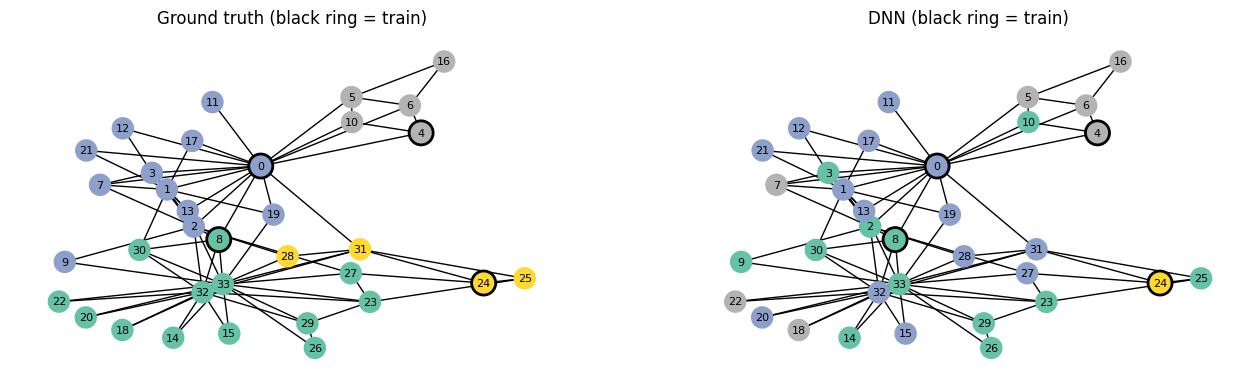

In [53]:
import networkx as nx
from torch_geometric.utils import to_networkx
import matplotlib.pyplot as plt

graph = to_networkx(data, to_undirected=True)
position = nx.spring_layout(graph, seed=42)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

for ax, labels, title in [(axes[0], data.y, "Ground truth"),
                            (axes[1], pred, f"DNN")]:
    nx.draw_networkx(graph, pos=position, ax=ax, node_color=labels.tolist(),
                        cmap="Set2", vmin=0, vmax=4 - 1,
                        node_size=230, font_size=8)
    nx.draw_networkx_nodes(graph, position, ax=ax,
                            nodelist=train_mask.nonzero(as_tuple=True)[0].tolist(),
                            node_size=300, node_color="none", edgecolors="black", linewidths=2)
    ax.set_title(title + " (black ring = train)")
    ax.axis("off")
